In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal as sps
from scipy.stats import skew, kurtosis
from sklearn.ensemble import RandomForestClassifier

from src.preprocessing import load_split, SUPERCLASSES, SAMPLING_RATE
from src.evaluation import tune_thresholds, compute_metrics
print("ferdig")

ferdig


In [2]:
X_tren, Y_tren, id_tren = load_split("train")
X_val, Y_val, id_val = load_split("val")
X_test, Y_test, id_test = load_split("test")

print("Trening:  ", X_tren.shape, Y_tren.shape)
print("Validering:", X_val.shape, Y_val.shape)
print("Test:     ", X_test.shape, Y_test.shape)
print("Klasser:", SUPERCLASSES)
print("Første etikett:", Y_tren[0])
print(f"Signalverdier: snitt {X_tren.mean():.3f}, std {X_tren.std():.3f}")

Trening:   (17083, 1000, 12) (17083, 5)
Validering: (2146, 1000, 12) (2146, 5)
Test:      (2158, 1000, 12) (2158, 5)
Klasser: ['NORM', 'MI', 'STTC', 'CD', 'HYP']
Første etikett: [1. 0. 0. 0. 0.]
Signalverdier: snitt 0.000, std 1.000


In [3]:
KANALER = ["I", "II", "III", "AVR", "AVL", "AVF",
           "V1", "V2", "V3", "V4", "V5", "V6"]
FS = SAMPLING_RATE  # 100 Hz

# Høypassfilter som fjerner baseline wander (alt under 0,5 Hz)
b, a = sps.butter(2, 0.5, btype="highpass", fs=FS)

def rr_trekk(kanal):
    topper, _ = sps.find_peaks(kanal, distance=int(0.3 * FS),
                               height=0.5 * np.max(kanal))
    if len(topper) < 2:
        return np.nan, np.nan
    rr = np.diff(topper) / FS
    return 60 / rr.mean(), rr.std()

def trekk_ut(sig):
    sig = sps.filtfilt(b, a, sig, axis=0)
    trekk = {}
    for i, navn in enumerate(KANALER):
        k = sig[:, i]
        trekk[f"{navn}_std"] = k.std()
        trekk[f"{navn}_min"] = k.min()
        trekk[f"{navn}_max"] = k.max()
        trekk[f"{navn}_skew"] = skew(k)
        trekk[f"{navn}_kurt"] = kurtosis(k)
    trekk["puls"], trekk["rr_std"] = rr_trekk(sig[:, 1])  # kanal II
    return trekk

test = trekk_ut(X_tren[0])
print(len(test), "egenskaper, puls:", round(test["puls"], 1))

62 egenskaper, puls: 63.9


In [4]:
def lag_tabell(X, navn):
    start = time.time()
    rader = [trekk_ut(sig) for sig in X]
    tabell = pd.DataFrame(rader)
    print(f"{navn}: {tabell.shape} på {time.time() - start:.0f} s, "
          f"uten puls: {tabell['puls'].isna().sum()}")
    return tabell

F_tren = lag_tabell(X_tren, "Trening")
F_val = lag_tabell(X_val, "Validering")
F_test = lag_tabell(X_test, "Test")

# Fyll manglende puls med medianen fra treningsdataene
median = F_tren.median()
F_tren = F_tren.fillna(median)
F_val = F_val.fillna(median)
F_test = F_test.fillna(median)
print("Manglende verdier igjen:", F_tren.isna().sum().sum())

Trening: (17083, 62) på 73 s, uten puls: 263
Validering: (2146, 62) på 10 s, uten puls: 45
Test: (2158, 62) på 10 s, uten puls: 38
Manglende verdier igjen: 0


In [5]:
modell = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42,
)

start = time.time()
modell.fit(F_tren, Y_tren)
treningstid = time.time() - start
print(f"Treningstid: {treningstid:.1f} s")

Treningstid: 1.2 s


In [6]:
def sannsynligheter(X):
    return np.column_stack([p[:, 1] for p in modell.predict_proba(X)])

# 1. Velg beste terskel per klasse på valideringssettet
p_val = sannsynligheter(F_val)
terskler = tune_thresholds(Y_val, p_val)

# 2. Evaluer på testsettet
start = time.time()
p_test = sannsynligheter(F_test)
tid_per_ekg = (time.time() - start) / len(F_test) * 1000

resultat = compute_metrics(Y_test, p_test, terskler)
resultat.to_csv("../results/rf_test_metrics.csv")
print(f"Tid per EKG: {tid_per_ekg:.3f} ms")
resultat.round(3)

Tid per EKG: 0.026 ms


,threshold,auc,precision,recall,f1,support
NORM,0.22,0.862,0.697,0.833,0.759,963.0
MI,0.44,0.811,0.522,0.658,0.582,550.0
STTC,0.45,0.818,0.503,0.678,0.577,521.0
CD,0.51,0.833,0.691,0.599,0.641,496.0
HYP,0.49,0.873,0.527,0.641,0.578,262.0
macro,NaN,0.839,0.588,0.682,0.628,2792.0


In [7]:
cnn = pd.read_csv("../results/cnn_test_metrics.csv", index_col=0)

sammenligning = pd.DataFrame({
    "CNN AUC": cnn["auc"],
    "RF AUC": resultat["auc"],
    "CNN recall": cnn["recall"],
    "RF recall": resultat["recall"],
    "CNN F1": cnn["f1"],
    "RF F1": resultat["f1"],
})
sammenligning.round(3)

,CNN AUC,RF AUC,CNN recall,RF recall,CNN F1,RF F1
NORM,0.944,0.862,0.891,0.833,0.860,0.759
MI,0.924,0.811,0.740,0.658,0.741,0.582
STTC,0.930,0.818,0.802,0.678,0.757,0.577
CD,0.918,0.833,0.732,0.599,0.751,0.641
HYP,0.905,0.873,0.664,0.641,0.603,0.578
macro,0.924,0.839,0.766,0.682,0.742,0.628


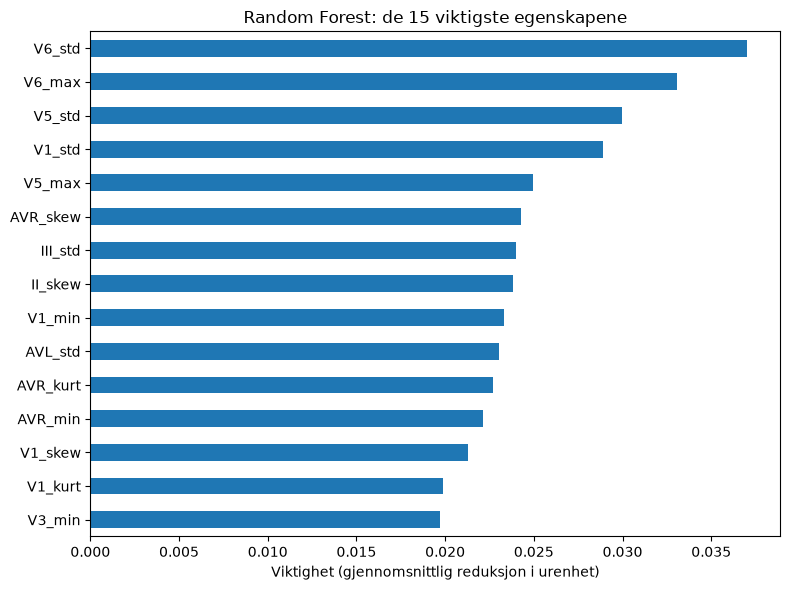

In [8]:
viktighet = pd.Series(modell.feature_importances_, index=F_tren.columns)
topp = viktighet.sort_values().tail(15)

topp.plot.barh(figsize=(8, 6))
plt.title("Random Forest: de 15 viktigste egenskapene")
plt.xlabel("Viktighet (gjennomsnittlig reduksjon i urenhet)")
plt.tight_layout()
plt.savefig("../results/rf_feature_importance.png", dpi=200)
plt.show()